In [7]:
import pandas as pd

df = pd.read_csv("C:/Users/Owner/DataPortfolio/airbnb-analysis/data/airbnb_listings.csv")

df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [11]:
df.info()

df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [14]:
df.groupby("neighbourhood_group")["price"].mean()

neighbourhood_group
Bronx             87.496792
Brooklyn         124.383207
Manhattan        196.875814
Queens            99.517649
Staten Island    114.812332
Name: price, dtype: float64

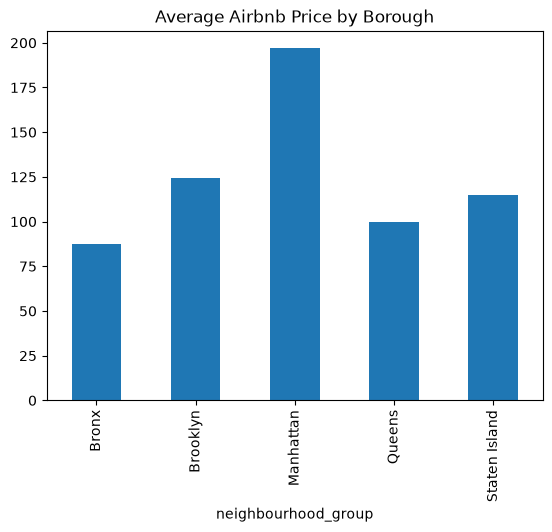

In [43]:
import matplotlib.pyplot as plt

df.groupby("neighbourhood_group")["price"].mean().plot(
    kind="bar"
)

plt.title("Average Airbnb Price by Borough")
plt.show()

In [19]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows: 48895
Columns: 16


In [20]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='str')

In [24]:
df.isnull().sum().sort_values(ascending=False)

last_review                       10052
reviews_per_month                 10052
host_name                            21
name                                 16
neighbourhood_group                   0
neighbourhood                         0
id                                    0
host_id                               0
longitude                             0
latitude                              0
room_type                             0
price                                 0
number_of_reviews                     0
minimum_nights                        0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [25]:
df["price"].describe()

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

In [27]:
df.groupby("neighbourhood_group")["price"].mean().sort_values(ascending=False)

neighbourhood_group
Manhattan        196.875814
Brooklyn         124.383207
Staten Island    114.812332
Queens            99.517649
Bronx             87.496792
Name: price, dtype: float64

Observation:
Manhattan has the highest average listing price.

In [28]:
df.groupby("room_type")["price"].mean().sort_values(ascending=False)

room_type
Entire home/apt    211.794246
Private room        89.780973
Shared room         70.127586
Name: price, dtype: float64

Observation:
Entire homes command a premium versus private rooms.

In [29]:
df["neighbourhood"].value_counts().head(10)

neighbourhood
Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1564
Midtown               1545
Name: count, dtype: int64

Observation:
Supply is most concentrated in Williamsburg, followed by Bedford-Stuyvesant, and Harlem.

In [33]:
display(df.isnull().sum().sort_values(ascending=False))

display(df.groupby("neighbourhood_group")["price"].mean().sort_values(ascending=False))

display(df.groupby("room_type")["price"].mean().sort_values(ascending=False))

last_review                       10052
reviews_per_month                 10052
host_name                            21
name                                 16
neighbourhood_group                   0
neighbourhood                         0
id                                    0
host_id                               0
longitude                             0
latitude                              0
room_type                             0
price                                 0
number_of_reviews                     0
minimum_nights                        0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

neighbourhood_group
Manhattan        196.875814
Brooklyn         124.383207
Staten Island    114.812332
Queens            99.517649
Bronx             87.496792
Name: price, dtype: float64

room_type
Entire home/apt    211.794246
Private room        89.780973
Shared room         70.127586
Name: price, dtype: float64

Displaying this stage of EDA findings all at once.

In [ ]:
df.count()["id"] # Experimenting

np.int64(48895)

In [38]:
df[df["reviews_per_month"].isnull()]["number_of_reviews"].describe()

count    10052.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: number_of_reviews, dtype: float64

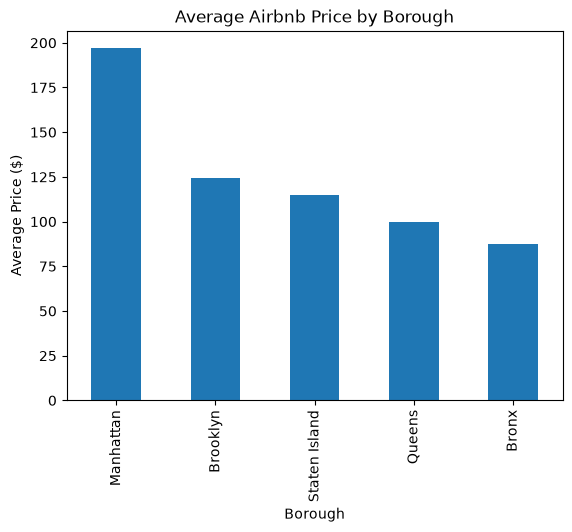

In [45]:
borough_prices = (
    df.groupby("neighbourhood_group")["price"]
      .mean()
      .sort_values(ascending=False)
)

borough_prices

import matplotlib.pyplot as plt

borough_prices.plot(kind="bar")

plt.title("Average Airbnb Price by Borough")
plt.xlabel("Borough")
plt.ylabel("Average Price ($)")
plt.show()

In [ ]:
211.79 / 89.78 # Entire homes earn roughly 2.4x the nightly rate of private rooms.

2.358988638895077

Entire-home listings generate significantly higher revenue potential than private or shared accommodations, suggesting hosts capable of offering dedicated units may benefit from substantially greater pricing power.

In [53]:
neighbourhood_summary = (
    df.groupby("neighbourhood")
      .agg({
          "price": "mean",
          "id": "count"
      })
      .rename(columns={"id": "listing_count"})
)

neighbourhood_summary.sort_values(
    by=["listing_count"],
    ascending=False
).head(20)

,price,listing_count
neighbourhood,,
Williamsburg,143.802806,3920
Bedford-Stuyvesant,107.678244,3714
Harlem,118.974041,2658
Bushwick,84.800406,2465
Upper West Side,210.918316,1971
Hell's Kitchen,204.794178,1958
East Village,186.083108,1853
Upper East Side,188.948276,1798
Crown Heights,112.480179,1564


## Initial Findings

1. Manhattan had the highest average listing price ($196.88), exceeding Brooklyn prices by approximately 58%.

2. Entire-home listings generated the highest average nightly rate ($211.79), approximately 2.4 times greater than private rooms.

3. Review-related fields contained approximately 20% missing values, likely indicating listings with little or no review activity rather than data-quality issues.

In [68]:
display(df["number_of_reviews"].describe())

display(df["availability_365"].describe())

count    48895.000000
mean        23.274466
std         44.550582
min          0.000000
25%          1.000000
50%          5.000000
75%         24.000000
max        629.000000
Name: number_of_reviews, dtype: float64

count    48895.000000
mean       112.781327
std        131.622289
min          0.000000
25%          0.000000
50%         45.000000
75%        227.000000
max        365.000000
Name: availability_365, dtype: float64

In [69]:
df[["price","number_of_reviews"]].corr(numeric_only=True)

,price,number_of_reviews
price,1.000000,-0.047954
number_of_reviews,-0.047954,1.000000


In [70]:
df[["price","availability_365"]].corr(numeric_only=True)

,price,availability_365
price,1.000000,0.081829
availability_365,0.081829,1.000000


In [71]:
df[["price","minimum_nights"]].corr(numeric_only=True)

,price,minimum_nights
price,1.000000,0.042799
minimum_nights,0.042799,1.000000


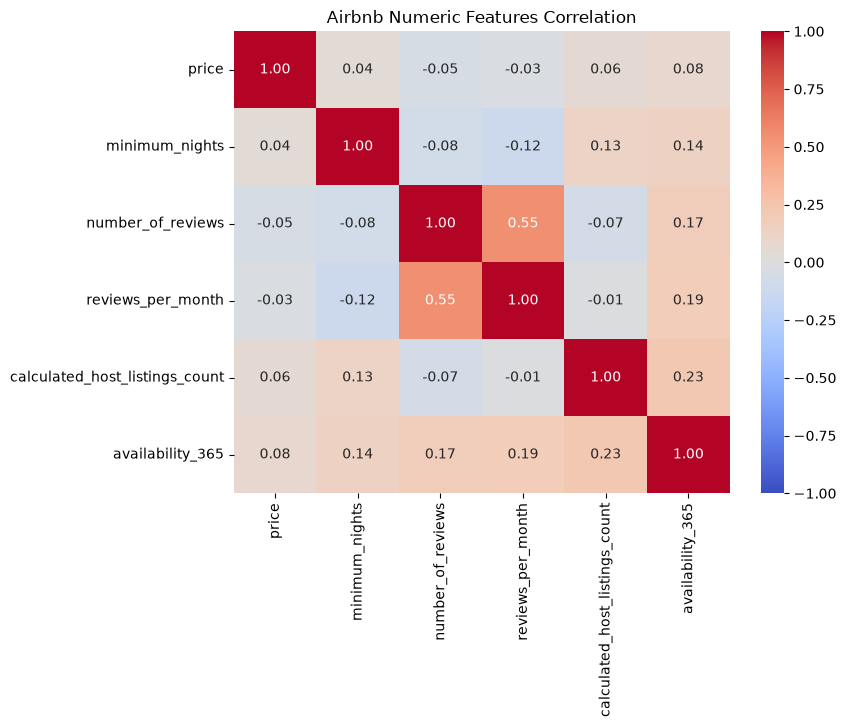

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only meaningful numeric columns from the Airbnb dataset
airbnb_cols = [
    "price", 
    "minimum_nights", 
    "number_of_reviews", 
    "reviews_per_month", 
    "calculated_host_listings_count", 
    "availability_365"
]

# Calculate correlation and plot
corr_matrix = df[airbnb_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Airbnb Numeric Features Correlation")
plt.show()

Shows the level of correlation between all columns in data

-1.0  = strong negative relationship
 0.0  = no relationship
+1.0  = strong positive relationship

*Used sample code from Google AI on correlation matrices.

In [73]:
df["price"].sort_values(ascending=False).head(20) # Looking for outliers

29238    10000
9151     10000
17692    10000
6530      9999
40433     9999
12342     9999
30268     8500
4377      8000
29662     7703
42523     7500
45666     7500
44034     6800
48043     6500
3774      6500
37194     6500
29664     6419
15560     6000
3537      6000
3720      5250
43009     5100
Name: price, dtype: int64

In [74]:
df["price"].quantile(0.99) # What does the top 1% look like?

np.float64(799.0)

In [75]:
host_summary = (
    df.groupby("host_id")
      .agg({
          "id":"count",
          "price":"mean"
      })
      .rename(columns={
          "id":"listing_count",
          "price":"avg_price"
      })
)

host_summary.sort_values(
    by="listing_count",
    ascending=False
).head(10)

,listing_count,avg_price
host_id,,
219517861,327,253.195719
107434423,232,303.150862
30283594,121,277.528926
137358866,103,43.825243
12243051,96,213.031250
16098958,96,208.958333
61391963,91,146.241758
22541573,87,215.436782
200380610,65,290.230769


Business Question: Is Airbnb mostly individuals renting spare rooms, or professional operators managing large inventories?

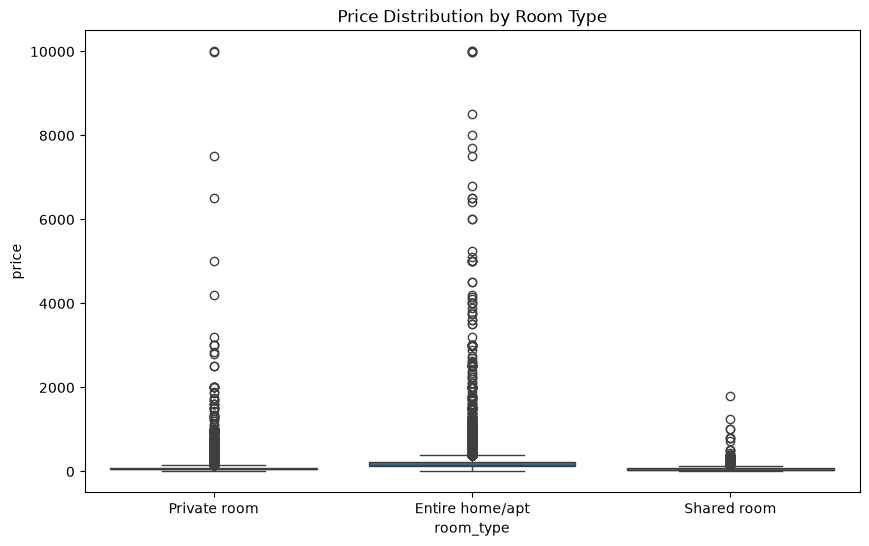

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="room_type",
    y="price"
)

plt.title("Price Distribution by Room Type")
plt.show()

In [78]:
df["price"].describe()

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

In [79]:
df["price"].quantile(0.99)

np.float64(799.0)

In [80]:
price_cutoff = df["price"].quantile(0.99)

df_clean = df[
    df["price"] <= price_cutoff
]

In [81]:
df.groupby(
    "neighbourhood_group"
)["price"].mean().sort_values(
    ascending=False
)

neighbourhood_group
Manhattan        196.875814
Brooklyn         124.383207
Staten Island    114.812332
Queens            99.517649
Bronx             87.496792
Name: price, dtype: float64

In [82]:
df_clean.groupby(
    "neighbourhood_group"
)["price"].mean().sort_values(
    ascending=False
)

neighbourhood_group
Manhattan        172.893774
Brooklyn         115.869357
Staten Island     94.241192
Queens            94.104779
Bronx             83.785846
Name: price, dtype: float64

Rows: 48895
